In [4]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pathlib

from naive_bayes.results import load_results, filter_df, get_best_params, add_params

In [6]:
RESULTS_PATH = pathlib.Path("../results")
DATASET_SELECTION = ["Amazon Books", "MIND", "ML25M"]
PRIMARY_METRIC = "Recall@25"

df_ease, df_knn, df_bernoulli, df_multinomial = load_results(RESULTS_PATH, include_pruning_results=True)

## Main results

In [ ]:
def add_identifier(df):
    def process_identifier(identifier):
        parameters = identifier.split('(')[1][:-1].split(',')
        algorithm = identifier.split('(')[0]
        parameter_dict = dict(map(lambda p: p.split('='), parameters))

        if algorithm == "ItemKNN":
            if parameter_dict["similarity"] == "cosine":
                return "kNN (cosine)"
            elif parameter_dict["similarity"] == "conditional_probability":
                return "kNN (cond. prob.)"
            else:
                return "-"
        elif algorithm == "EASE":
            return "EASE"
        elif algorithm == "BernoulliNB":
            return "NB (Bernoulli)"
        elif algorithm == "MultinomialNB":
            return "NB (multinomial)"
        
    df["identifier"] = df["identifier"].map(process_identifier)
    return df

def print_final_results(dataset_name, df, metrics):
    agg = df.groupby("identifier").mean()
    agg2 = df.groupby("identifier").sem()
    agg["relative_fit_time"] = agg["fit_time"] / agg.loc["EASE"]["fit_time"]
    agg2["relative_fit_time"] = 0
    print(f"\\multirow{{{len(agg)}}}{{*}}{{{dataset_name}}}")
    for (alg, results), (_, sem) in zip(agg.iterrows(), agg2.iterrows()):
        line = ""
        for metric in metrics:
            line += f" & {results[metric]:.3f} $\\pm${sem[metric]:.3f}"
        print(f"& {alg:>17}{line} \\\\")
    print(f"\\cmidrule(lr){{1-{len(metrics)+2}}}")

In [10]:
final_amazon_books = add_identifier(pd.read_csv(RESULTS_PATH / "amazon_books_final.csv"))
final_mind = add_identifier(pd.read_csv(RESULTS_PATH / "mind_final.csv"))
final_ml25m = add_identifier(pd.read_csv(RESULTS_PATH / "ml25m_final.csv"))

print_final_results("Amazon Books", final_amazon_books, ["Recall@10", "NDCG@10", "Recall@25", "NDCG@25", "Recall@50", "NDCG@50", "relative_fit_time"])
print_final_results("MIND", final_mind, ["Recall@10", "NDCG@10", "Recall@25", "NDCG@25", "Recall@50", "NDCG@50", "relative_fit_time"])
print_final_results("ML25M", final_ml25m, ["Recall@10", "NDCG@10", "Recall@25", "NDCG@25", "Recall@50", "NDCG@50", "relative_fit_time"])

\multirow{5}{*}{Amazon Books}
&              EASE & 0.251 0.001 & 0.195 0.000 & 0.349 0.001 & 0.226 0.001 & 0.433 0.001 & 0.249 0.000 & 1.000 0.000 \\
&    NB (Bernoulli) & 0.207 0.001 & 0.156 0.001 & 0.305 0.001 & 0.186 0.001 & 0.397 0.001 & 0.210 0.000 & 0.063 0.000 \\
&  NB (multinomial) & 0.221 0.001 & 0.167 0.001 & 0.324 0.001 & 0.198 0.000 & 0.421 0.001 & 0.224 0.000 & 0.040 0.000 \\
& kNN (cond. prob.) & 0.146 0.001 & 0.104 0.001 & 0.227 0.001 & 0.128 0.001 & 0.310 0.001 & 0.150 0.000 & 0.023 0.000 \\
&      kNN (cosine) & 0.170 0.001 & 0.127 0.000 & 0.252 0.001 & 0.152 0.000 & 0.336 0.001 & 0.174 0.000 & 0.008 0.000 \\
\cmidrule(lr){1-9}
\multirow{5}{*}{MIND}
&              EASE & 0.169 0.001 & 0.105 0.000 & 0.276 0.001 & 0.135 0.000 & 0.378 0.001 & 0.158 0.000 & 1.000 0.000 \\
&    NB (Bernoulli) & 0.162 0.001 & 0.100 0.000 & 0.268 0.001 & 0.129 0.000 & 0.373 0.001 & 0.153 0.000 & 0.078 0.000 \\
&  NB (multinomial) & 0.168 0.001 & 0.103 0.001 & 0.274 0.001 & 0.133 0.001 & 0.38

## Bias

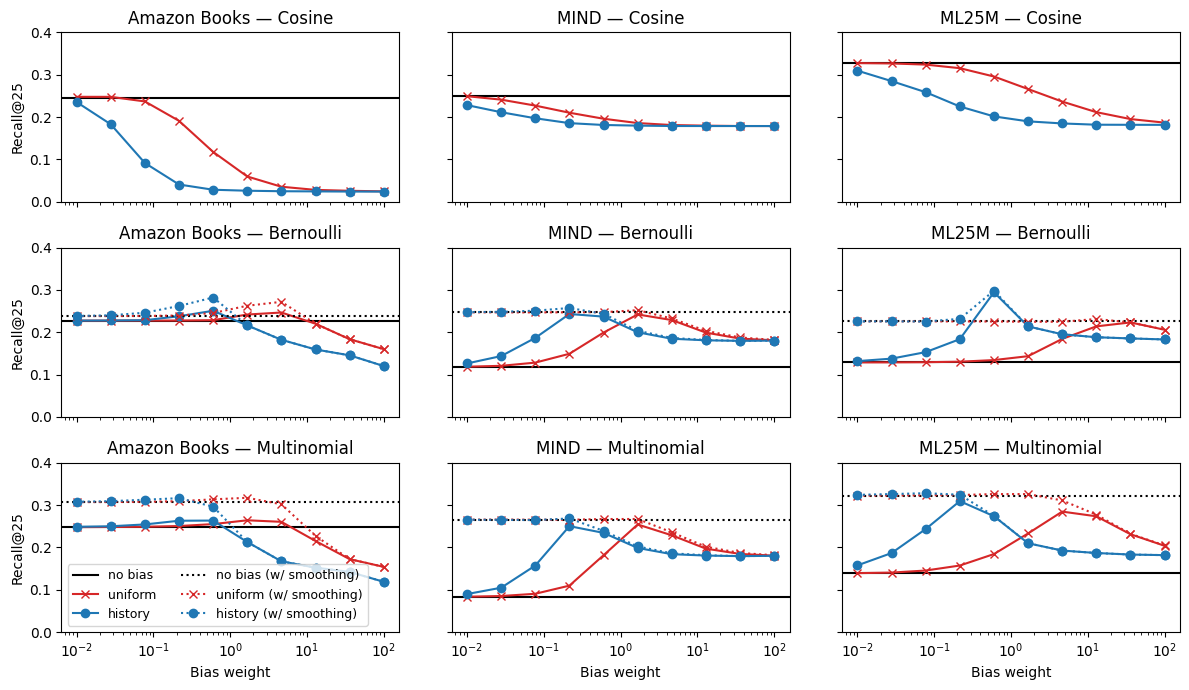

In [ ]:
def plot_bias(ax, df, metric, with_smoothing=False):
    df_no_bias = df[df["bias_weight"] == 0]
    df_uniform = df[(df["bias_weight"] != 0) & (df["bias_weight_modifier"] == "constant")]
    df_history = df[(df["bias_weight"] != 0) & (df["bias_weight_modifier"] == "history")]
    if with_smoothing:
        ax.axhline(df_no_bias[metric].max(), linestyle="dotted", label="no bias (w/ smoothing)", color="black")
        ax.plot(df_uniform.groupby("bias_weight")[metric].max().sort_index(), marker="x", label="uniform (w/ smoothing)", color="tab:red", linestyle="dotted")
        ax.plot(df_history.groupby("bias_weight")[metric].max().sort_index(), marker="o", label="history (w/ smoothing)", color="tab:blue", linestyle="dotted")
    else:
        ax.axhline(df_no_bias[metric].max(), label="no bias", color="black")
        ax.plot(df_uniform.groupby("bias_weight")[metric].max().sort_index(), marker="x", label="uniform", color="tab:red")
        ax.plot(df_history.groupby("bias_weight")[metric].max().sort_index(), marker="o", label="history", color="tab:blue")
    ax.set_xscale("log")
    ax.set_ylim(0, 0.4)
    

def fig_bias(metric: str):
    fig, axes = plt.subplots(3,3, sharex=True, sharey=True, figsize=(12, 7))
    for column, dataset_name in enumerate(DATASET_SELECTION):
        plot_bias(axes[0][column], filter_df(df_knn, similarity="cosine", dataset=dataset_name), metric, False)
        plot_bias(axes[1][column], filter_df(df_bernoulli, dataset=dataset_name, bias_event_model="bernoulli", weights_smoothing_strength=0), metric, False)
        plot_bias(axes[2][column], filter_df(df_multinomial, dataset=dataset_name, bias_event_model="multinomial", weights_smoothing_strength=0), metric, False)
        plot_bias(axes[1][column], filter_df(df_bernoulli, dataset=dataset_name, bias_event_model="bernoulli", weights_smoothing_type="uniform"), metric, True)
        plot_bias(axes[2][column], filter_df(df_multinomial, dataset=dataset_name, bias_event_model="multinomial", weights_smoothing_type="uniform"), metric, True)
        axes[0][column].set_title(f"{dataset_name} — Cosine")
        axes[1][column].set_title(f"{dataset_name} — Bernoulli")
        axes[2][column].set_title(f"{dataset_name} — Multinomial")
        axes[2][column].set_xlabel("Bias weight")
    axes[0][0].set_ylabel(metric)
    axes[1][0].set_ylabel(metric)
    axes[2][0].set_ylabel(metric)
    axes[2][0].legend(loc="lower left", ncols=2, fontsize=9)
    fig.tight_layout()
    return fig

fig_bias(PRIMARY_METRIC).savefig("../plots/bias.png")

## Smoothing

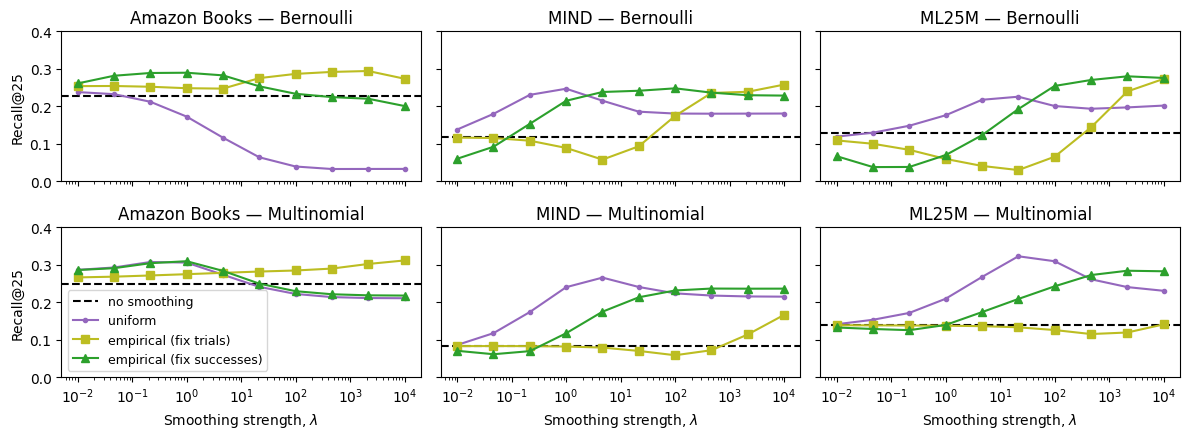

In [ ]:
def plot_smoothing(ax, df, metric):
    df_no_smoothing = df[df["weights_smoothing_strength"] == 0]
    df_uniform = df[(df["weights_smoothing_type"] == "uniform") & (df["weights_smoothing_strength"] != 0)]
    df_empirical1 = df[(df["weights_smoothing_type"] == "empirical1") & (df["weights_smoothing_strength"] != 0)]
    df_empirical2 = df[(df["weights_smoothing_type"] == "empirical2") & (df["weights_smoothing_strength"] != 0)]
    ax.axhline(df_no_smoothing[metric].max(), color="black", linestyle="dashed", label="no smoothing")
    ax.plot(df_uniform.groupby("weights_smoothing_strength")[metric].max(), label="uniform", color="tab:purple", marker=".")
    ax.plot(df_empirical1.groupby("weights_smoothing_strength")[metric].max(), label="empirical (fix trials)", color="tab:olive", marker="s")
    ax.plot(df_empirical2.groupby("weights_smoothing_strength")[metric].max(), label="empirical (fix successes)", color="tab:green", marker="^")
    ax.set_xscale("log")
    ax.set_ylim(0, 0.4)

def fig_smoothing(metric: str):
    fig, axes = plt.subplots(2,3, sharex=True, sharey=True, figsize=(12, 4.5))
    for column, dataset_name in enumerate(DATASET_SELECTION):
        plot_smoothing(axes[0][column], filter_df(df_bernoulli, dataset=dataset_name, bias_weight=0), metric)
        plot_smoothing(axes[1][column], filter_df(df_multinomial, dataset=dataset_name, bias_weight=0), metric)
        axes[0, column].set_title(f"{dataset_name} — Bernoulli")
        axes[1, column].set_title(f"{dataset_name} — Multinomial")
        axes[1, column].set_xlabel("Smoothing strength, $\\lambda$")
    axes[0, 0].set_ylabel(metric)
    axes[1, 0].set_ylabel(metric)
    axes[1, 0].legend(fontsize=9)
    fig.tight_layout()
    return fig

fig_smoothing(PRIMARY_METRIC).savefig("../plots/smoothing.png")

## Pruning

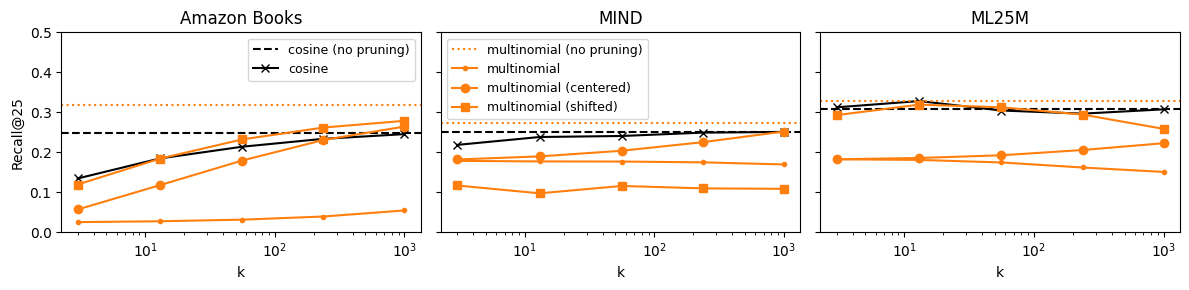

In [ ]:
def plot_pruning(ax, df1, df2, metric):
    l1 = ax.axhline(df1[df1["max_k"] == 1000000][metric].max(), linestyle="dashed", label="cosine (no pruning)", color="black")
    l2, = ax.plot(df1[df1["max_k"] != 1000000].groupby("max_k")[metric].max().sort_index(), marker="x", label="cosine", color="black")
    l3 = ax.axhline(df2[df2["max_k"] == 1000000][metric].max(), linestyle="dotted", label="multinomial (no pruning)", color="tab:orange")
    l4, = ax.plot(df2[(df2["max_k"] != 1000000) & (~df2["centering"]) & (df2["absolute_pruning"])].groupby("max_k")[metric].max().sort_index(), marker=".", label="multinomial", color="tab:orange")
    l5, = ax.plot(df2[(df2["max_k"] != 1000000) & (df2["centering"]) & (df2["absolute_pruning"])].groupby("max_k")[metric].max().sort_index(), marker="o", label="multinomial (centered)", color="tab:orange")
    l6, = ax.plot(df2[(df2["max_k"] != 1000000) & (~df2["centering"]) & (~df2["absolute_pruning"])].groupby("max_k")[metric].max().sort_index(), marker="s", label="multinomial (shifted)", color="tab:orange")
    ax.set_xscale("log")
    ax.set_ylim(0, 0.5)
    return [l1, l2], [l3, l4, l5, l6]
    

def fig_pruning(metric: str):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
    for column, dataset_name in enumerate(DATASET_SELECTION):
        h1, h2 = plot_pruning(axes[column], filter_df(df_knn, similarity="cosine", dataset=dataset_name), filter_df(df_multinomial, dataset=dataset_name), metric)
        axes[column].set_title(dataset_name)
        axes[column].set_xlabel("k")
        if column == 0:
            axes[column].legend(fontsize=9, loc="upper right", handles=h1)
        if column == 1:
            axes[column].legend(fontsize=9, loc="upper left", handles=h2)
    axes[0].set_ylabel(metric)
    fig.tight_layout()
    return fig

fig_pruning(PRIMARY_METRIC).savefig("../plots/pruning.png")

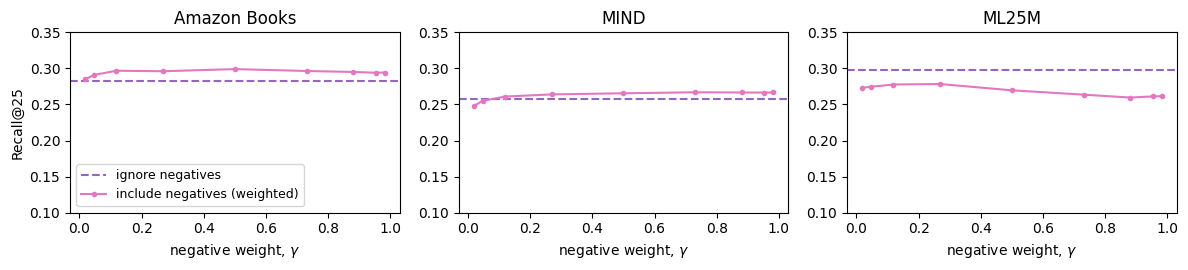

In [ ]:
def plot_complement_weight(ax, df, metric: str):
    df1 = df[df.weights_complement_weight == df.model_complement_weight]
    df2 = filter_df(df, weights_complement_weight=1.0, model_complement_weight=0.0)
    ax.axhline(df2[metric].max(), linestyle="dashed", color="tab:purple", label="ignore negatives")
    ax.plot(df1.groupby("weights_complement_weight")[metric].max(), marker=".", color="tab:pink", label="include negatives (weighted)")
    ax.set_ylim(0.1, 0.35)
    

def fig_complement_weight(metric: str):
    fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
    for column, dataset_name in enumerate(DATASET_SELECTION):
        plot_complement_weight(axes[column], filter_df(df_bernoulli, dataset=dataset_name), metric)
        axes[column].set_title(dataset_name)
        axes[column].set_xlabel("negative weight, $\\gamma$")
    axes[0].set_ylabel(metric)
    axes[0].legend(loc="lower left", fontsize=9)
    # axes[0].set_ylim(0.22, 0.32)
    # axes[1].set_ylim(0.22, 0.32)
    # axes[2].set_ylim(0, 0.35)
    fig.tight_layout()
    return fig

fig_complement_weight(PRIMARY_METRIC).savefig("../plots/negatives.png")

## Dataset Statistics

In [ ]:
from naive_bayes.datasets import load_ml25m, load_amazon_books, load_mind
from naive_bayes.datasets.utils import create_interaction_array

def print_dataset_statistics(X, label):
    user_count, item_count = X.shape
    interaction_count = X.nnz
    density = interaction_count / (user_count * item_count)
    print(f"{label} & {item_count:,} & {user_count:,}  & {interaction_count:,} & {density:.2%} \\\\".replace("%", r"\%"))

print_dataset_statistics(create_interaction_array(load_ml25m()[0]), "ML25M")
print_dataset_statistics(create_interaction_array(load_amazon_books()), "Amazon Books")
print_dataset_statistics(create_interaction_array(load_mind()[0]), "MIND")

ML25M & 19,935 & 160,770  & 12,411,442 & 0.39\% \\
Amazon Books & 13,800 & 142,399  & 2,933,904 & 0.15\% \\
MIND & 9,353 & 267,545  & 2,868,403 & 0.11\% \\
